# Procedural animation

A scene for ``python -m svgwriter animate``. The ``Orbit`` scene draws a sun, an orbit path and a planet
in ``build`` and moves the planet in ``update(seconds)``; the animate command renders one frame per time
step.

    python -m svgwriter animate examples/10_procedural_animation/procedural_animation.py --format gif
    python procedural_animation.py                  writes the first frame as SVG

In [1]:
import math

import svgwriter as svg

A scene is a class. Its attributes set the canvas size, frame rate, length and renderer; `build`
draws into an empty document of that size and keeps the planet on `self` for later.

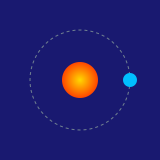

In [2]:
ORBIT = 50


class Orbit(svg.Scene):
    width = height = 160
    fps = 24
    duration = 2.0

    def build(self, doc: svg.Document) -> None:
        center = self.width / 2
        glow = doc.radial_gradient(svg.Stop(0, "gold"), svg.Stop(1, "orangered"))
        doc.rect(0, 0, self.width, self.height, fill="midnightblue")
        doc.circle(center, center, ORBIT, fill="none", stroke="slategray", stroke_dasharray=(3, 3))
        doc.circle(center, center, 18, fill=glow)
        self.planet = doc.circle(center + ORBIT, center, 7, fill="deepskyblue")

    def update(self, seconds: float) -> None:
        angle = 2 * math.pi * seconds / self.duration
        center = self.width / 2
        self.planet.cx = center + ORBIT * math.cos(angle)
        self.planet.cy = center + ORBIT * math.sin(angle)


scene = Orbit()
scene

`update` sets the planet's position for a given time. Calling it with a quarter of the duration
moves the planet a quarter of the way round.

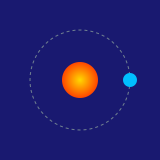

In [3]:
scene.update(Orbit.duration / 4)
scene

Back to the first frame and save it. `scene.save("orbit.gif")` would encode every frame with ffmpeg.
This cell is skipped when `svgwriter animate` loads the script.

In [4]:
if __name__ == "__main__":
    scene.update(0)
    scene.document.save("10_orbit_frame0.svg")